In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_recall_curve
)

print("FactoryPulse ML environment ready!")

FactoryPulse ML environment ready!


In [2]:
from pathlib import Path
import pandas as pd

# Define the dataset location
dataset_path = Path(
    r"C:\FactoryPulse\data\processed\ai4i_processed.csv"
)

# Load the dataset
df = pd.read_csv(dataset_path)

# Display the first 5 rows
display(df.head())

,udi,product_id,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf,air_temperature_c,process_temperature_c,temperature_difference_c
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,24.95,35.45,10.5
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,25.05,35.55,10.5
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,24.95,35.35,10.4
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,25.05,35.45,10.4
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,25.05,35.55,10.5


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["machine_failure"].value_counts())

Dataset shape: (10000, 17)

Column names:
['udi', 'product_id', 'type', 'air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure', 'twf', 'hdf', 'pwf', 'osf', 'rnf', 'air_temperature_c', 'process_temperature_c', 'temperature_difference_c']

Missing values:
udi                         0
product_id                  0
type                        0
air_temperature_k           0
process_temperature_k       0
rotational_speed_rpm        0
torque_nm                   0
tool_wear_min               0
machine_failure             0
twf                         0
hdf                         0
pwf                         0
osf                         0
rnf                         0
air_temperature_c           0
process_temperature_c       0
temperature_difference_c    0
dtype: int64

Target distribution:
machine_failure
0    9661
1     339
Name: count, dtype: int64


In [4]:
# Input features (X)
features = [
    "type",
    "air_temperature_k",
    "process_temperature_k",
    "rotational_speed_rpm",
    "torque_nm",
    "tool_wear_min"
]

X = df[features]

# Prediction target (y)
y = df["machine_failure"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (10000, 6)
Target shape: (10000,)


,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


In [5]:
X_encoded = pd.get_dummies(
    X,
    columns=["type"],
    drop_first=False,
    dtype=int
)

display(X_encoded.head())

print("Encoded features:", X_encoded.columns.tolist())
print("Encoded shape:", X_encoded.shape)

,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,type_H,type_L,type_M
0,298.1,308.6,1551,42.8,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,1,0
2,298.1,308.5,1498,49.4,5,0,1,0
3,298.2,308.6,1433,39.5,7,0,1,0
4,298.2,308.7,1408,40.0,9,0,1,0


Encoded features: ['air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'type_H', 'type_L', 'type_M']
Encoded shape: (10000, 8)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 8)
Testing features: (2000, 8)

Training target distribution:
machine_failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
machine_failure
0    1932
1      68
Name: count, dtype: int64


In [7]:
from sklearn.linear_model import LogisticRegression

# Create the model
log_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train using training data
log_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [8]:
# Predict machine failures on unseen test data
y_pred_log = log_model.predict(X_test)

# Get probability of machine failure
y_prob_log = log_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred_log[:10])

print("\nFirst 10 failure probabilities:")
print(y_prob_log[:10])

First 10 predictions:
[1 0 1 0 1 1 1 0 0 1]

First 10 failure probabilities:
[0.97334804 0.48898357 0.6614897  0.01498413 0.85509955 0.6504712
 0.80535537 0.13892565 0.02805197 0.58607137]


In [9]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_log,
        target_names=["Normal", "Failure"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.99      0.83      0.90      1932
     Failure       0.14      0.82      0.24        68

    accuracy                           0.83      2000
   macro avg       0.57      0.83      0.57      2000
weighted avg       0.96      0.83      0.88      2000



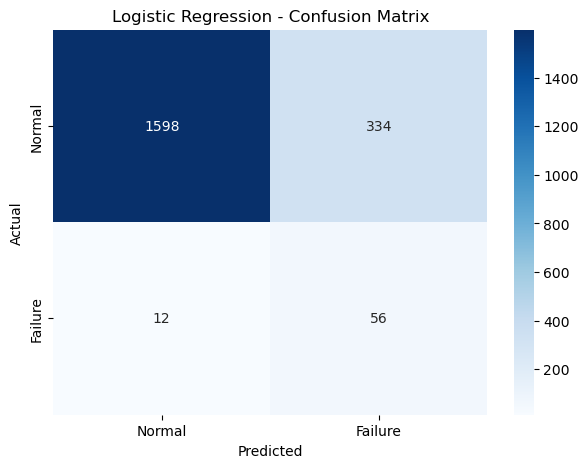

Confusion matrix:
[[1598  334]
 [  12   56]]


In [10]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_log)

# Visualize results
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Failure"],
    yticklabels=["Normal", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

print("Confusion matrix:")
print(cm)

In [11]:
from sklearn.metrics import average_precision_score

pr_auc_log = average_precision_score(y_test, y_prob_log)

print(f"Logistic Regression PR-AUC: {pr_auc_log:.4f}")

Logistic Regression PR-AUC: 0.3963


In [12]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [13]:
# Predict failure classes
y_pred_rf = rf_model.predict(X_test)

# Get failure probabilities
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred_rf[:10])

print("\nFirst 10 failure probabilities:")
print(y_prob_rf[:10])

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 failure probabilities:
[0.3125313  0.         0.11641772 0.01262136 0.11176511 0.0031149
 0.0162433  0.         0.         0.21578279]


In [14]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Normal", "Failure"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      1932
     Failure       0.85      0.65      0.73        68

    accuracy                           0.98      2000
   macro avg       0.92      0.82      0.86      2000
weighted avg       0.98      0.98      0.98      2000



In [15]:
from sklearn.metrics import average_precision_score

pr_auc_rf = average_precision_score(y_test, y_prob_rf)

print(f"Logistic Regression PR-AUC: {pr_auc_log:.4f}")
print(f"Random Forest PR-AUC: {pr_auc_rf:.4f}")

Logistic Regression PR-AUC: 0.3963
Random Forest PR-AUC: 0.7669


In [16]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Normal", "Failure"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      1932
     Failure       0.85      0.65      0.73        68

    accuracy                           0.98      2000
   macro avg       0.92      0.82      0.86      2000
weighted avg       0.98      0.98      0.98      2000



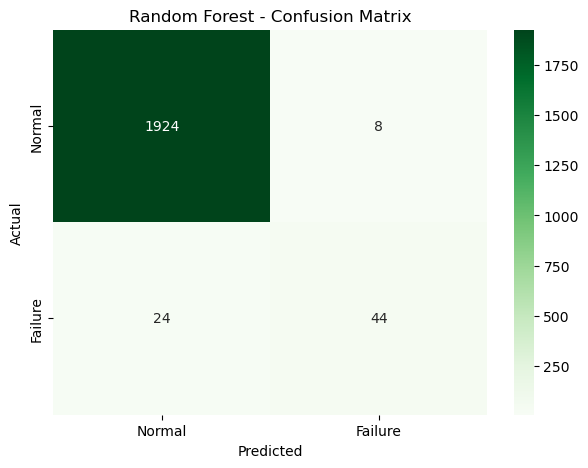

In [17]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Normal", "Failure"],
    yticklabels=["Normal", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [18]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate permutation importance
result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create a results table
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean
})

# Sort from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
2,rotational_speed_rpm,0.439495
3,torque_nm,0.437260
0,air_temperature_k,0.324550
4,tool_wear_min,0.262327
1,process_temperature_k,0.106264
6,type_L,0.010836
5,type_H,0.003924
7,type_M,-0.008932


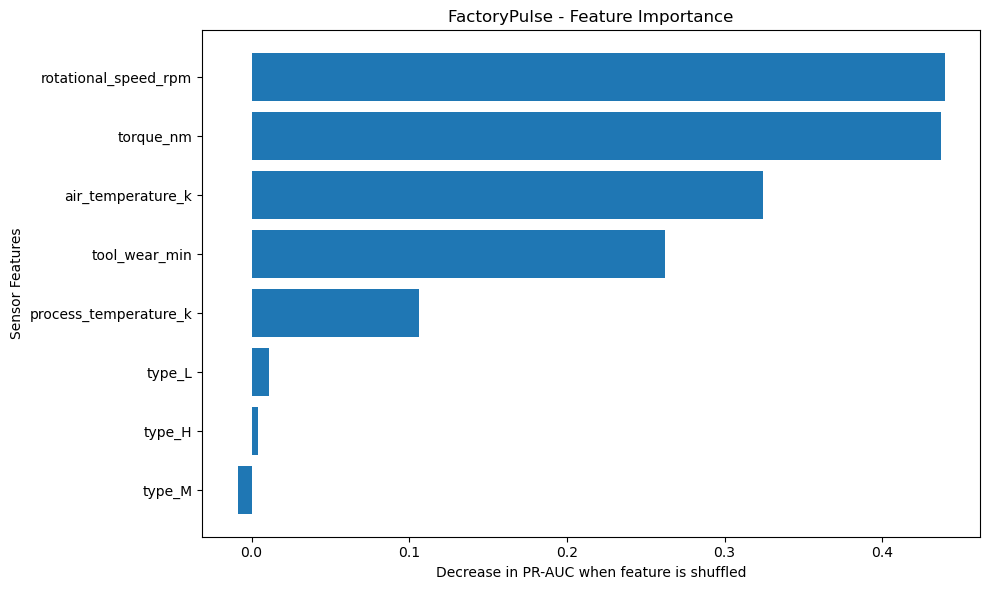

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Decrease in PR-AUC when feature is shuffled")
plt.ylabel("Sensor Features")
plt.title("FactoryPulse - Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [20]:
from pathlib import Path
import pandas as pd

from sklearn.inspection import permutation_importance

# Output directory
output_dir = Path(r"C:\FactoryPulse\data\processed")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Calculate explainable feature importance
result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean,
    "importance_std": result.importances_std
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

# 2. Prepare test observations
predictions = df.loc[
    X_test.index,
    [
        "udi",
        "product_id",
        "type",
        "air_temperature_c",
        "process_temperature_c",
        "rotational_speed_rpm",
        "torque_nm",
        "tool_wear_min"
    ]
].copy()

# 3. Add actual and predicted results
predictions["actual_failure"] = y_test
predictions["predicted_failure"] = y_pred_rf
predictions["failure_probability_pct"] = y_prob_rf * 100

predictions["prediction_result"] = predictions[
    "predicted_failure"
].map({
    0: "Predicted Normal",
    1: "Predicted Failure"
})

# 4. Export both files
predictions.to_csv(
    output_dir / "factorypulse_predictions.csv",
    index=False
)

feature_importance.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

print("Files exported successfully!")
print("Predictions:", predictions.shape)
print("Feature importance:", feature_importance.shape)

display(feature_importance)
display(predictions.head())

Files exported successfully!
Predictions: (2000, 12)
Feature importance: (8, 3)


,feature,importance,importance_std
2,rotational_speed_rpm,0.439495,0.021104
3,torque_nm,0.437260,0.030126
0,air_temperature_k,0.324550,0.056587
4,tool_wear_min,0.262327,0.026841
1,process_temperature_k,0.106264,0.035469
6,type_L,0.010836,0.016094
5,type_H,0.003924,0.005536
7,type_M,-0.008932,0.008841


,udi,product_id,type,air_temperature_c,process_temperature_c,rotational_speed_rpm,torque_nm,tool_wear_min,actual_failure,predicted_failure,failure_probability_pct,prediction_result
2997,2998,L50177,L,27.35,36.65,1345,62.7,153,0,0,31.253130,Predicted Normal
4871,4872,L52051,L,30.55,39.25,1513,40.1,135,0,0,0.000000,Predicted Normal
3858,3859,L51038,L,29.35,38.25,1559,37.6,209,0,0,11.641772,Predicted Normal
951,952,H30365,H,22.45,33.15,1509,35.8,60,0,0,1.262136,Predicted Normal
6463,6464,H35877,H,27.35,36.85,1358,60.4,102,0,0,11.176511,Predicted Normal


In [21]:
import joblib
from pathlib import Path

model_dir = Path(r"C:\FactoryPulse\models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    rf_model,
    model_dir / "random_forest_model.pkl"
)

joblib.dump(
    list(X_train.columns),
    model_dir / "model_features.pkl"
)

print("Model saved successfully!")

Model saved successfully!
